# 5장 기대 모델 변화와 기대 오차 감소

라벨을 붙인 뒤의 결과를 기댓값으로 계산하는 결정 이론 기반 질의 전략을 다룬다. 기대 기울기 길이(EGL)는 싸고 기대 오차 감소(EER)는 비싸다. 마지막 절은 1부 전략 전체를 한 표로 묶는다.

- 5.1 결정 이론 기반 질의 전략
- 5.2 기대 기울기 길이(EGL)
- 5.3 기대 오차 감소(EER)
- 5.4 분산 감소
- 5.5 계산 비용과 후보 부분 표본
- 5.6 1부 질의 전략 종합 비교

CPU만으로 돈다. EER은 축소 설정(엔트로피 상위 후보, 평가 부분집합 1,000개, 예산 1,000, 시드 3개)으로 돌린다. 5.3절 첫 셀이 한 라운드 시간을 재서 전체 예상 시간을 출력한다. 실험은 (전략, 시드) 조합을 joblib으로 CPU 코어에 나눠 돌린다. 결과 수치는 순차 실행과 같지만, 라운드당 질의 시간은 여러 작업이 코어를 함께 쓰므로 순차로 돈 3장 값보다 조금 길게 잡힐 수 있다. 3·4장 노트북이 만든 `results/ch03_*.csv`, `results/ch04_*.csv` 를 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

## 5.2 기대 기울기 길이(EGL)

로지스틱 회귀의 로그 손실 기울기는 (p − e_y)xᵀ이고 그 노름은 ‖p − e_y‖·‖x‖다. 절편 기울기까지 넣으면 ‖x‖ 대신 √(‖x‖² + 1)이 된다. 가능한 라벨 y에 대해 현재 모델 확률로 가중평균한다.

In [3]:
# ── 기대 기울기 길이 ────
def score_egl(P, X):
    E = np.eye(P.shape[1])
    g = np.sqrt(((P[:, None, :] - E[None]) ** 2).sum(2))              # 라벨 y마다 ‖p − e_y‖
    x_norm = np.sqrt(np.asarray(X.multiply(X).sum(1)).ravel() + 1)    # 절편 포함 √(‖x‖² + 1)
    return (P * g).sum(1) * x_norm

def query_egl(model, data, idx_l, y_l, idx_u, k, rng):
    X = data["X_pool"][idx_u]
    return idx_u[np.argsort(-score_egl(proba(model, X, data["n_classes"]), X))[:k]]

In [4]:
# ── 특징 노름과 엔트로피와의 순위 상관 ────
for name, d in DATA.items():
    norms = np.sqrt(np.asarray(d["X_pool"].multiply(d["X_pool"]).sum(1)).ravel())
    idx = np.random.default_rng(0).choice(len(d["y_pool"]), N_INIT, replace=False)
    P = proba(train_model(d["X_pool"][idx], d["y_pool"][idx], 0), d["X_pool"], d["n_classes"])
    S = pd.DataFrame({"EGL": score_egl(P, d["X_pool"]), "엔트로피": score_entropy(P)})
    print(f"{name}: ‖x‖ 최소 {norms.min():.4f} 최대 {norms.max():.4f}, "
          f"EGL-엔트로피 Spearman {S.corr(method='spearman').iloc[0, 1]:.4f}")

nsmc: ‖x‖ 최소 0.0000 최대 1.0000, EGL-엔트로피 Spearman 0.9999


ynat: ‖x‖ 최소 1.0000 최대 1.0000, EGL-엔트로피 Spearman 0.9968


In [5]:
# ── EGL 실험 ────
BASE = {"EGL": query_egl, "엔트로피": make_score_query(score_entropy), "Random": query_random}
res = {name: run_strategies(BASE, d) for name, d in DATA.items()}
for name, r in res.items():
    print(f"\n{name} (F1)")
    print(summarize(r, "f1").to_string(index=False))

nsmc  EGL, 엔트로피, Random 완료


ynat  EGL, 엔트로피, Random 완료

nsmc (F1)
strategy    ALC  ALC_std  final     LE  t_query
     EGL 0.7472   0.0053 0.7852 1.1429   0.0211
    엔트로피 0.7479   0.0055 0.7860 1.2121   0.0079
  Random 0.7426   0.0034 0.7802 1.0000   0.0000

ynat (F1)
strategy    ALC  ALC_std  final     LE  t_query
     EGL 0.6144   0.0085 0.7198 1.9048   0.0492
    엔트로피 0.6164   0.0048 0.7202 2.0000   0.0278
  Random 0.5335   0.0068 0.6500 1.0000   0.0001


## 5.3 기대 오차 감소(EER)

후보 x와 가능한 라벨 y마다 (x, y)를 더해 모델을 다시 학습하고 평가 부분집합의 기대 엔트로피(로그 손실 근사)를 계산한다. 재학습은 현재 모델의 가중치에서 이어 시작한다(웜 스타트). 가상 라벨은 현재 모델이 아는 클래스로 한정한다. 모르는 클래스의 확률은 0이라 기댓값에 기여하지 않는다.

In [6]:
# ── 기대 오차 감소 ────
import copy
from scipy.sparse import vstack

EER_BUDGET, EER_SEEDS, N_EVAL = 1000, [0, 1, 2], 1000
EER_CAND = {"nsmc": 100, "ynat": 100}   # 후보 수는 질의 크기 K(50)보다 커야 EER 점수가 고르는 데 쓰인다

def fit_plus(model, X_l, y_l, x, y, warm):
    m = copy.deepcopy(model).set_params(warm_start=warm)
    return m.fit(vstack([X_l, x]), np.r_[y_l, y])

def make_eer_query(n_cand, n_eval=N_EVAL, risk_fn=score_entropy, warm=True):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        X, C = data["X_pool"], data["n_classes"]
        cand = idx_u[np.argsort(-score_entropy(proba(model, X[idx_u], C)))[:n_cand]]
        ev = rng.choice(idx_u, n_eval, replace=False)
        P_c, X_l = proba(model, X[cand], C), X[idx_l]
        risk = np.array([sum(P_c[i, y] * risk_fn(proba(fit_plus(model, X_l, y_l, X[x], y, warm), X[ev], C)).mean()
                             for y in model.classes_)
                         for i, x in enumerate(cand)])
        return cand[np.argsort(risk)[:k]]
    return query_fn

In [7]:
# ── EER 한 라운드 시간과 전체 예상 시간 ────
for name, d in DATA.items():
    rng = np.random.default_rng(0)
    idx_l = rng.choice(len(d["y_pool"]), N_INIT, replace=False)
    idx_u = np.setdiff1d(np.arange(len(d["y_pool"])), idx_l)
    model = train_model(d["X_pool"][idx_l], d["y_pool"][idx_l], 0)
    t0 = time.perf_counter()
    make_eer_query(EER_CAND[name])(model, d, idx_l, d["y_pool"][idx_l], idx_u, K, rng)
    t = time.perf_counter() - t0
    rounds = (EER_BUDGET - N_INIT) // K
    print(f"{name}: 후보 {EER_CAND[name]}개 한 라운드 {t:.1f}초, 예상 {t * rounds * len(EER_SEEDS) / 60:.0f}분 이상")

nsmc: 후보 100개 한 라운드 1.1초, 예상 1분 이상


ynat: 후보 100개 한 라운드 47.1초, 예상 42분 이상


In [8]:
# ── EER 축소 실험 ────
eer = {name: run_strategies({"EER": make_eer_query(EER_CAND[name]),
                             "엔트로피": make_score_query(score_entropy), "Random": query_random},
                            d, seeds=EER_SEEDS, budget=EER_BUDGET)
       for name, d in DATA.items()}
for name, r in eer.items():
    r.to_csv(f"results/ch05_eer_{name}.csv", index=False)
    print(f"\n{name} 예산 {EER_BUDGET}, 시드 {len(EER_SEEDS)}개 (F1)")
    print(summarize(r, "f1", budget=EER_BUDGET).to_string(index=False))

nsmc  EER, 엔트로피, Random 완료


ynat  EER, 엔트로피, Random 완료

nsmc 예산 1000, 시드 3개 (F1)
strategy    ALC  ALC_std  final     LE  t_query
     EER 0.7245   0.0044 0.7629 1.2500   2.0926
    엔트로피 0.7188   0.0089 0.7581 1.0526   0.0080
  Random 0.7109   0.0091 0.7535 1.0526   0.0000

ynat 예산 1000, 시드 3개 (F1)
strategy    ALC  ALC_std  final     LE  t_query
     EER 0.5228   0.0106 0.6427 1.6667 110.1210
    엔트로피 0.5292   0.0005 0.6515 1.8182   0.0470
  Random 0.4552   0.0091 0.5626 1.0000   0.0001


## 5.5 계산 비용과 후보 부분 표본

NSMC에서 EER 후보 수를 75, 100, 200으로 바꾸고 웜 스타트 유무에 따른 한 라운드 시간을 잰다. 후보 수별 학습 곡선은 계산량 때문에 시드 0 하나로만 돌린다.

In [9]:
# ── 후보 크기와 계산 시간 ────
d = DATA["nsmc"]
rng = np.random.default_rng(0)
idx_l = rng.choice(len(d["y_pool"]), N_INIT, replace=False)
idx_u = np.setdiff1d(np.arange(len(d["y_pool"])), idx_l)
model = train_model(d["X_pool"][idx_l], d["y_pool"][idx_l], 0)
CANDS = [75, 100, 200]          # 모두 K=50보다 크다
rows = []
for n_cand in CANDS:
    for warm in (True, False):
        t0 = time.perf_counter()
        make_eer_query(n_cand, warm=warm)(model, d, idx_l, d["y_pool"][idx_l], idx_u, K, np.random.default_rng(0))
        rows.append(dict(후보=n_cand, 웜스타트=warm, 초=round(time.perf_counter() - t0, 2)))
print(pd.DataFrame(rows).to_string(index=False))

cand_res = run_strategies({f"EER 후보{c}": make_eer_query(c) for c in CANDS}, d, seeds=[0], budget=EER_BUDGET)
cand_res.to_csv("results/ch05_cand_nsmc.csv", index=False)
print(pd.DataFrame([dict(strategy=n, ALC=round(alc(g.n_labeled.values, g.f1.values, EER_BUDGET), 4),
                         final=round(g.f1.iloc[-1], 4), t_query=round(g.t_query.mean(), 2))
                    for n, g in cand_res.groupby("strategy", sort=False)]).to_string(index=False))

 후보  웜스타트    초
 75  True 0.84
 75 False 2.46
100  True 1.15
100 False 3.21
200  True 2.28
200 False 6.43


nsmc  EER 후보75, EER 후보100, EER 후보200 완료
 strategy    ALC  final  t_query
 EER 후보75 0.7244 0.7565     2.06
EER 후보100 0.7297 0.7646     2.63
EER 후보200 0.7305 0.7647     3.95


## 5.6 1부 질의 전략 종합 비교

Random, 엔트로피, EGL은 이 장의 결과를, 마진과 최소 신뢰도는 3장 결과를, QBC는 4장의 최선 설정을 쓴다. Random과 엔트로피는 3장 값과 같은지 대조한다. EER은 예산이 1,000이라 모든 전략을 [100, 1,000] 구간 지표로 한 번 더 비교한다.

In [10]:
# ── 1부 종합 비교 ────
summary = []
for name, d in DATA.items():
    ch03 = pd.read_csv(f"results/ch03_{name}.csv")
    ch04 = pd.read_csv(f"results/ch04_{name}.csv")
    for s in ("Random", "엔트로피"):
        diff = np.abs(ch03[ch03.strategy == s].f1.values - res[name][res[name].strategy == s].f1.values).max()
        print(name, s, "3장 대비 F1 최대 차이:", diff)
    s4 = summarize(ch04, "f1")
    best = s4[~s4.strategy.isin(["Random", "엔트로피"])].sort_values("ALC").strategy.iloc[-1]
    full = pd.concat([res[name], ch03[ch03.strategy.isin(["마진", "최소 신뢰도"])], ch04[ch04.strategy == best]],
                     ignore_index=True)
    part = pd.concat([full, eer[name][eer[name].strategy == "EER"]], ignore_index=True)
    t2000 = summarize(full, "f1")[["strategy", "ALC", "LE", "final"]]
    t1000 = summarize(part, "f1", budget=EER_BUDGET)[["strategy", "ALC", "final", "t_query"]]
    t = t1000.merge(t2000, on="strategy", how="left", suffixes=("@1000", "@2000")).assign(data=name)
    summary.append(t)
    print(f"\n{name} 1부 종합 (F1)")
    print(t.to_string(index=False))
summary = pd.concat(summary, ignore_index=True)
summary.to_csv("results/part1_summary.csv", index=False)

nsmc Random 3장 대비 F1 최대 차이: 5.551115123125783e-17
nsmc 엔트로피 3장 대비 F1 최대 차이: 5.551115123125783e-17

nsmc 1부 종합 (F1)
strategy  ALC@1000  final@1000  t_query  ALC@2000     LE  final@2000 data
     EGL    0.7184      0.7578   0.0226    0.7472 1.1429      0.7852 nsmc
    엔트로피    0.7184      0.7584   0.0082    0.7479 1.2121      0.7860 nsmc
  Random    0.7131      0.7530   0.0000    0.7426 1.0000      0.7802 nsmc
      마진    0.7184      0.7584   0.0035    0.7479 1.2121      0.7860 nsmc
  최소 신뢰도    0.7184      0.7584   0.0037    0.7479 1.2121      0.7860 nsmc
  배깅5·투표    0.7149      0.7587   0.7853    0.7469 1.2500      0.7876 nsmc
     EER    0.7245      0.7629   2.0926       NaN    NaN         NaN nsmc
ynat Random 3장 대비 F1 최대 차이: 8.326672684688674e-17
ynat 엔트로피 3장 대비 F1 최대 차이: 8.326672684688674e-17

ynat 1부 종합 (F1)
strategy  ALC@1000  final@1000  t_query  ALC@2000     LE  final@2000 data
     EGL    0.5330      0.6495   0.0461    0.6144 1.9048      0.7198 ynat
    엔트로피    0.5317      0.6532

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (14 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


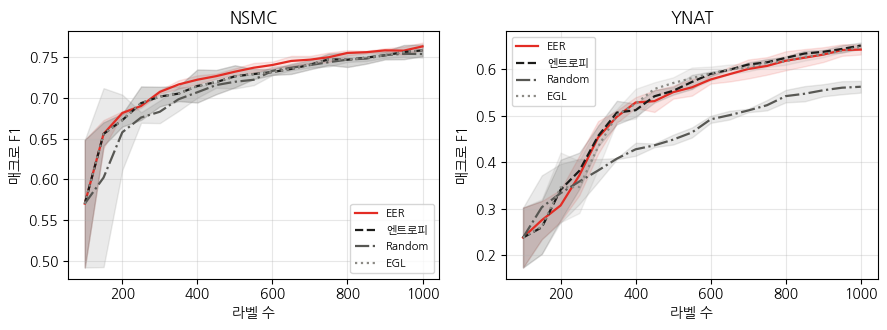

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


In [11]:
# ── 학습 곡선 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, eer.items()):
    plot_curves(pd.concat([r, res[name][(res[name].strategy == "EGL") & res[name].seed.isin(EER_SEEDS)
                                        & (res[name].n_labeled <= EER_BUDGET)]]), "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch05_curves.png", dpi=200)

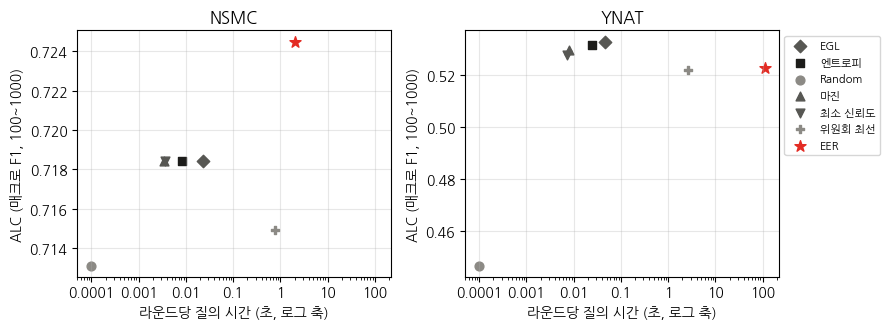

In [12]:
# ── 비용 대비 성능 그림 ────
MARK = {"Random": (GRAY2, "o"), "최소 신뢰도": (GRAY, "v"), "마진": (GRAY, "^"), "엔트로피": (INK, "s"),
        "EGL": (GRAY, "D"), "위원회 최선": (GRAY2, "P"), "EER": (ACCENT, "*")}
committee = ~summary.strategy.isin(list(MARK))
plot_df = summary.assign(strategy=summary.strategy.where(~committee, "위원회 최선"),
                         t=summary.t_query.clip(lower=1e-4))   # 질의 시간 0(Random)은 로그 축에 그리려고 1e-4로 올린다
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
for ax, (name, g) in zip(axes, plot_df.groupby("data")):
    for _, row in g.iterrows():
        c, mk = MARK[row.strategy]
        ax.scatter(row.t, row["ALC@1000"], color=c, marker=mk, s=70 if mk == "*" else 40, label=row.strategy)
    ax.set(xscale="log", title=name.upper(), xlabel="라운드당 질의 시간 (초, 로그 축)", ylabel="ALC (매크로 F1, 100~1000)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))   # 10의 음수 거듭제곱 표기 대신 소수로 쓴다
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig("out/ch05_cost_vs_alc.png", dpi=200)